In [9]:
# import sys
# from osgeo import gdal
# import matplotlib.pyplot as plt
# import numpy as np


import matplotlib.pyplot as plt
from osgeo import gdal


def show_tif(file_path):
    """Read and display a TIFF file using GDAL."""
    dataset = gdal.Open(file_path)

    if dataset is None:
        raise FileNotFoundError(f"Could not open: {file_path}")

    image = dataset.ReadAsArray()

    plt.imshow(image, cmap="gray")
    plt.colorbar()
    plt.show()


# Active Contour Model

The active contour model is a method to fit open or closed splines to lines or
edges in an image [1]_. It works by minimising an energy that is in part
defined by the image and part by the spline's shape: length and smoothness. The
minimization is done implicitly in the shape energy and explicitly in the
image energy.

In the following two examples the active contour model is used (1) to segment
the face of a person from the rest of an image by fitting a closed curve
to the edges of the face and (2) to find the darkest curve between two fixed
points while obeying smoothness considerations. Typically it is a good idea to
smooth images a bit before analyzing, as done in the following examples.

We initialize a circle around the astronaut's face and use the default boundary
condition ``boundary_condition='periodic'`` to fit a closed curve. The default
parameters ``w_line=0, w_edge=1`` will make the curve search towards edges,
such as the boundaries of the face.

.. [1] *Snakes: Active contour models*. Kass, M.; Witkin, A.; Terzopoulos, D.
       International Journal of Computer Vision 1 (4): 321 (1988).
       :DOI:`10.1007/BF00133570`


# 0. read raster

In [10]:
# data_path="/archive/depfg/data/chelsa/tas"
# file_name="CHELSA_tas_13_02_2023_V.2.1.tif"


# in_file = os.path.join(data_path, file_name)

in_file = "data/Delta_ClassProbability_tile_9.tif"

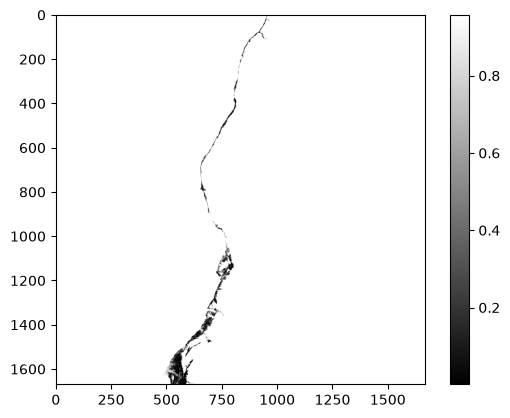

In [11]:
show_tif(in_file)

In [16]:
import numpy as np
from osgeo import gdal

in_file = "data/Delta_ClassProbability_tile_9.tif"

dataset = gdal.Open(in_file)

if dataset is None:
    raise FileNotFoundError(f"Could not open: {in_file}")

band = dataset.GetRasterBand(1)
data = band.ReadAsArray()

print("Shape:", data.shape)
print("Data type:", data.dtype)
print("Minimum:", np.nanmin(data))
print("Maximum:", np.nanmax(data))

# Unique values
unique_values = np.unique(data)

print("Number of unique values:", len(unique_values))

if len(unique_values <= 20):
    print("Unique values:")
    print(unique_values)
else:
    print("First 20 unique values:")
    print(unique_values[:20])

Shape: (1670, 1670)
Data type: float64
Minimum: 0.0011258919945991046
Maximum: 0.9575190702272284
Number of unique values: 24418
Unique values:
[0.00112589 0.00121187 0.00121513 ... 0.95441593 0.95751907        nan]


Shape: (1670, 1670)
Min: 0.0011258919945991046
Max: 0.9575190702272284
Number of NaN: 2764382
Total pixels: 2788900
NaN fraction: 0.9912087202839829


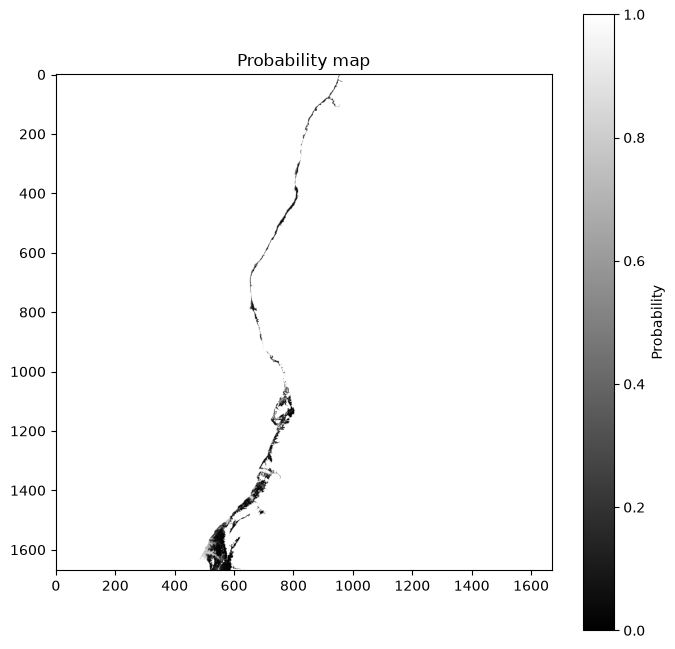

In [17]:
import numpy as np
from osgeo import gdal

in_file = "data/Delta_ClassProbability_tile_9.tif"

dataset = gdal.Open(in_file)
probability = dataset.GetRasterBand(1).ReadAsArray()

print("Shape:", probability.shape)
print("Min:", np.nanmin(probability))
print("Max:", np.nanmax(probability))
print("Number of NaN:", np.isnan(probability).sum())
print("Total pixels:", probability.size)
print("NaN fraction:", np.isnan(probability).mean())

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 8))

plt.imshow(
    probability,
    cmap="gray",
    vmin=0,
    vmax=1,
)

plt.title("Probability map")
plt.colorbar(label="Probability")
plt.show()

In [23]:
import numpy as np
import matplotlib.pyplot as plt

from osgeo import gdal
from skimage.filters import gaussian
from skimage.segmentation import active_contour

NaN count: 0
Minimum: 0.0
Maximum: 0.9575190702272284


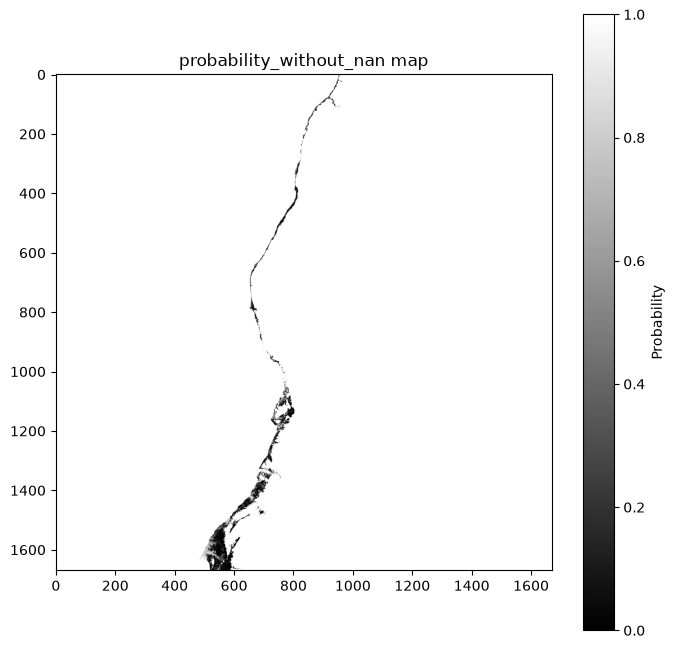

In [25]:
# Convert to float
probability_without_nan = probability.astype(float)

# Replace NaN with zero probability
probability_without_nan[np.isnan(probability_without_nan)] = 0.0

print("NaN count:", np.isnan(probability_without_nan).sum())
print("Minimum:", probability_without_nan.min())
print("Maximum:", probability_without_nan.max())


# Smooth probability map
img_smooth = gaussian(
    probability_without_nan,
    sigma=3,
    preserve_range=True,
)

plt.figure(figsize=(8, 8))

plt.imshow(
    probability,
    cmap="gray",
    vmin=0,
    vmax=1,
)

plt.title("probability_without_nan map")
plt.colorbar(label="Probability")
plt.show()

# 1. shape energy optimization

Shape: (1670, 1670)
Data type: float64
Minimum: 0.0011258919945991046
Maximum: 0.9575190702272284
center_row,center_col:  1400 700


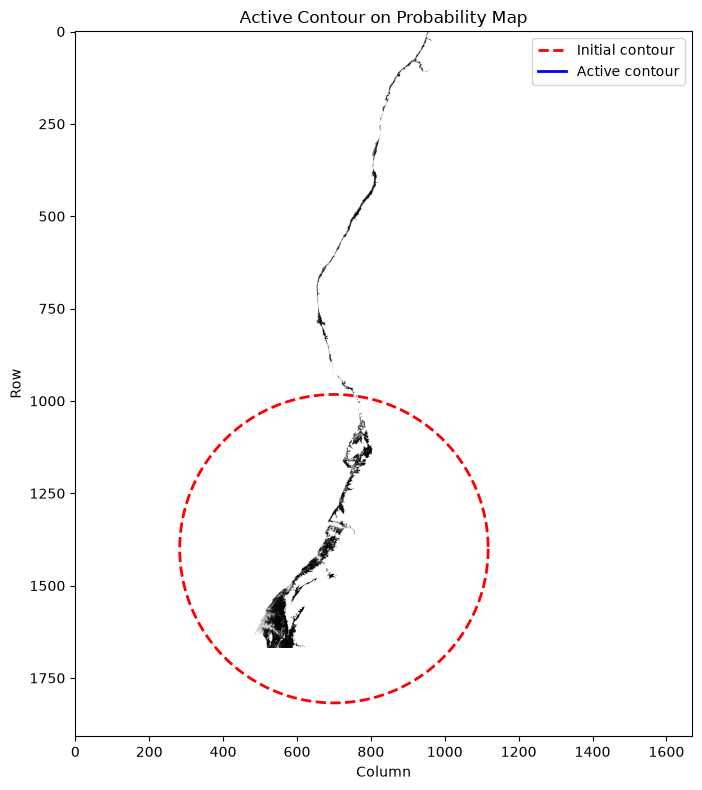

In [19]:
import numpy as np
import matplotlib.pyplot as plt

from osgeo import gdal
from skimage.filters import gaussian
from skimage.segmentation import active_contour


# =========================================================
# 1. Read probability map
# =========================================================

file_name = "data/Delta_ClassProbability_tile_9.tif"

dataset = gdal.Open(file_name)

if dataset is None:
    raise FileNotFoundError(f"Could not open: {file_name}")

probability = dataset.GetRasterBand(1).ReadAsArray()

print("Shape:", probability.shape)
print("Data type:", probability.dtype)
print("Minimum:", np.nanmin(probability))
print("Maximum:", np.nanmax(probability))


# Convert to float
img = probability.astype(float)


# =========================================================
# 2. Smooth probability map
# =========================================================

img_smooth = gaussian(
    img,
    sigma=3,
    preserve_range=True,
)


# =========================================================
# 3. Define initial circular contour
# =========================================================

s = np.linspace(0, 2 * np.pi, 400)

# Change these values for your region
center_row = 1400  # img.shape[0] / 2
center_col = 700  # img.shape[1] / 2

print("center_row,center_col: ", center_row, center_col)

radius = min(img.shape) * 0.25

r = center_row + radius * np.sin(s)
c = center_col + radius * np.cos(s)

init = np.column_stack((r, c))


# =========================================================
# 4. Run active contour
# =========================================================

snake = active_contour(
    img_smooth,
    init,
    alpha=0.015,
    beta=10,
    gamma=0.001,
)


# =========================================================
# 5. Plot
# =========================================================

fig, ax = plt.subplots(figsize=(8, 8))

ax.imshow(
    img,
    cmap="gray",
    vmin=0,
    vmax=1,
)

ax.plot(
    init[:, 1],
    init[:, 0],
    "--r",
    linewidth=2,
    label="Initial contour",
)

ax.plot(
    snake[:, 1],
    snake[:, 0],
    "-b",
    linewidth=2,
    label="Active contour",
)

ax.set_title("Active Contour on Probability Map")
ax.set_xlabel("Column")
ax.set_ylabel("Row")
ax.legend()

plt.tight_layout()
plt.show()

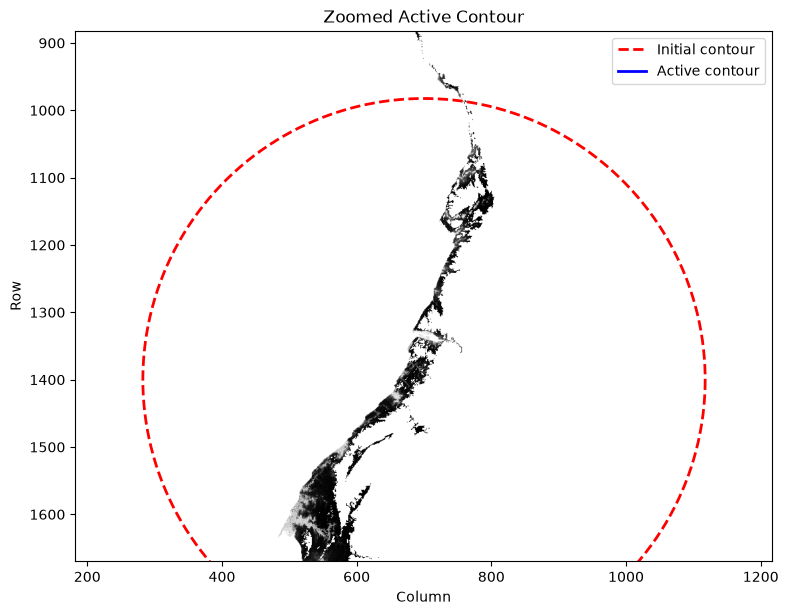

In [20]:
# =========================================================
# 6. Zoomed plot around the active contour
# =========================================================

margin = 100

row_min = int(np.min(init[:, 0])) - margin
row_max = int(np.max(init[:, 0])) + margin
col_min = int(np.min(init[:, 1])) - margin
col_max = int(np.max(init[:, 1])) + margin

# Keep indices inside the image
row_min = max(0, row_min)
row_max = min(img.shape[0], row_max)
col_min = max(0, col_min)
col_max = min(img.shape[1], col_max)

fig, ax = plt.subplots(figsize=(8, 8))

ax.imshow(
    img,
    cmap="gray",
    vmin=0,
    vmax=1,
)

ax.plot(
    init[:, 1],
    init[:, 0],
    "--r",
    linewidth=2,
    label="Initial contour",
)

ax.plot(
    snake[:, 1],
    snake[:, 0],
    "-b",
    linewidth=2,
    label="Active contour",
)

# Zoom to the contour
ax.set_xlim(col_min, col_max)
ax.set_ylim(row_max, row_min)

ax.set_xlabel("Column")
ax.set_ylabel("Row")
ax.set_title("Zoomed Active Contour")
ax.legend()

plt.tight_layout()
plt.show()

In [21]:
print("Active contour coordinates:")
print(snake)

Active contour coordinates:
[[nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [na

## 1.1. Shape energy optimization for non values are replaced with 0

center_row,center_col:  1400 700


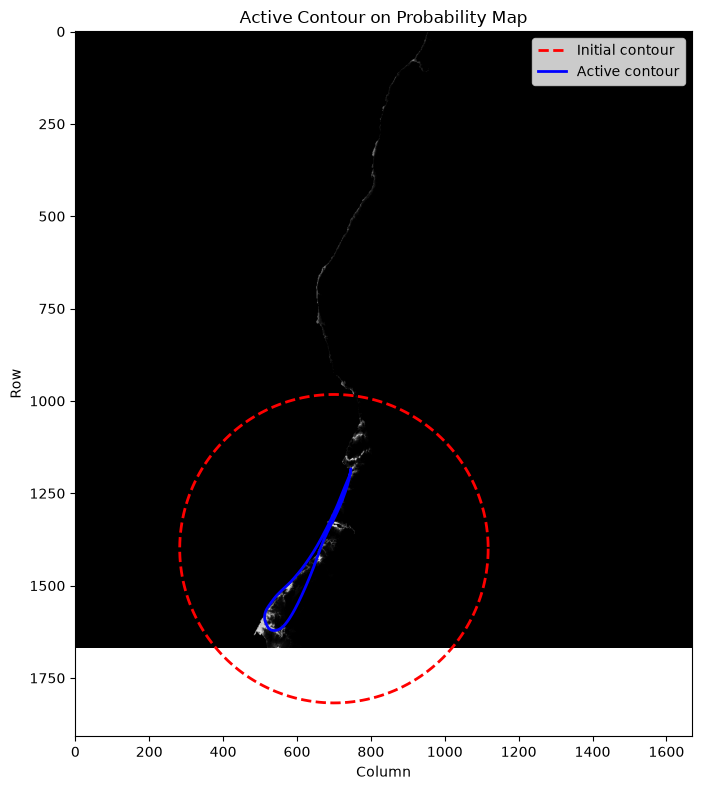

In [26]:
import numpy as np
import matplotlib.pyplot as plt

from osgeo import gdal
from skimage.filters import gaussian
from skimage.segmentation import active_contour


# =========================================================
# 1. Read probability map
# =========================================================

# file_name = "data/Delta_ClassProbability_tile_9.tif"

# dataset = gdal.Open(file_name)

# if dataset is None:
#     raise FileNotFoundError(f"Could not open: {file_name}")

# probability = dataset.GetRasterBand(1).ReadAsArray()

# print("Shape:", probability.shape)
# print("Data type:", probability.dtype)
# print("Minimum:", np.nanmin(probability))
# print("Maximum:", np.nanmax(probability))


# Convert to float
img = probability_without_nan.astype(float)


# =========================================================
# 2. Smooth probability map
# =========================================================

img_smooth = gaussian(
    img,
    sigma=3,
    preserve_range=True,
)


# =========================================================
# 3. Define initial circular contour
# =========================================================

s = np.linspace(0, 2 * np.pi, 400)

# Change these values for your region
center_row = 1400  # img.shape[0] / 2
center_col = 700  # img.shape[1] / 2

print("center_row,center_col: ", center_row, center_col)

radius = min(img.shape) * 0.25

r = center_row + radius * np.sin(s)
c = center_col + radius * np.cos(s)

init = np.column_stack((r, c))


# =========================================================
# 4. Run active contour
# =========================================================

snake = active_contour(
    img_smooth,
    init,
    alpha=0.015,
    beta=10,
    gamma=0.001,
)


# =========================================================
# 5. Plot
# =========================================================

fig, ax = plt.subplots(figsize=(8, 8))

ax.imshow(
    img,
    cmap="gray",
    vmin=0,
    vmax=1,
)

ax.plot(
    init[:, 1],
    init[:, 0],
    "--r",
    linewidth=2,
    label="Initial contour",
)

ax.plot(
    snake[:, 1],
    snake[:, 0],
    "-b",
    linewidth=2,
    label="Active contour",
)

ax.set_title("Active Contour on Probability Map")
ax.set_xlabel("Column")
ax.set_ylabel("Row")
ax.legend()

plt.tight_layout()
plt.show()

In [28]:
print("Active contour coordinates:")
print(snake)

Active contour coordinates:
[[1330.53516273  694.28762548]
 [1333.31215507  692.88064758]
 [1336.0894999   691.46911806]
 [1338.86933641  690.05485748]
 [1341.65359049  688.6411997 ]
 [1344.44407664  687.23258628]
 [1347.24233289  685.83392674]
 [1350.05036679  684.44924805]
 [1352.87022239  683.08137586]
 [1355.70342816  681.73190418]
 [1358.55070027  680.40123761]
 [1361.41196395  679.0889309 ]
 [1364.28642575  677.79414077]
 [1367.17274467  676.5157597 ]
 [1370.06928464  675.25265254]
 [1372.97452734  674.00375322]
 [1375.88736887  672.76826736]
 [1378.80720007  671.54591624]
 [1381.73379559  670.33700685]
 [1384.66721625  669.14232194]
 [1387.60839422  667.96286069]
 [1390.55934507  666.79988338]
 [1393.5220212   665.65432561]
 [1396.49712389  664.52563071]
 [1399.48379145  663.41108123]
 [1402.48093392  662.30728016]
 [1405.48731979  661.21151437]
 [1408.50152234  660.12167263]
 [1411.52203173  659.03597013]
 [1414.54735965  657.9529447 ]
 [1417.5773836   656.87131206]
 [1420.6140

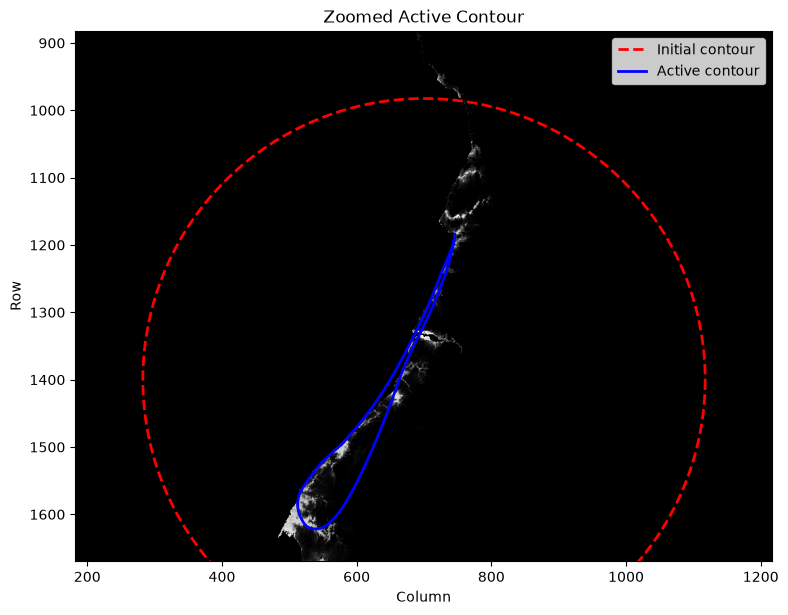

In [27]:
# =========================================================
# 6. Zoomed plot around the active contour
# =========================================================

margin = 100

row_min = int(np.min(init[:, 0])) - margin
row_max = int(np.max(init[:, 0])) + margin
col_min = int(np.min(init[:, 1])) - margin
col_max = int(np.max(init[:, 1])) + margin

# Keep indices inside the image
row_min = max(0, row_min)
row_max = min(img.shape[0], row_max)
col_min = max(0, col_min)
col_max = min(img.shape[1], col_max)

fig, ax = plt.subplots(figsize=(8, 8))

ax.imshow(
    img,
    cmap="gray",
    vmin=0,
    vmax=1,
)

ax.plot(
    init[:, 1],
    init[:, 0],
    "--r",
    linewidth=2,
    label="Initial contour",
)

ax.plot(
    snake[:, 1],
    snake[:, 0],
    "-b",
    linewidth=2,
    label="Active contour",
)

# Zoom to the contour
ax.set_xlim(col_min, col_max)
ax.set_ylim(row_max, row_min)

ax.set_xlabel("Column")
ax.set_ylabel("Row")
ax.set_title("Zoomed Active Contour")
ax.legend()

plt.tight_layout()
plt.show()

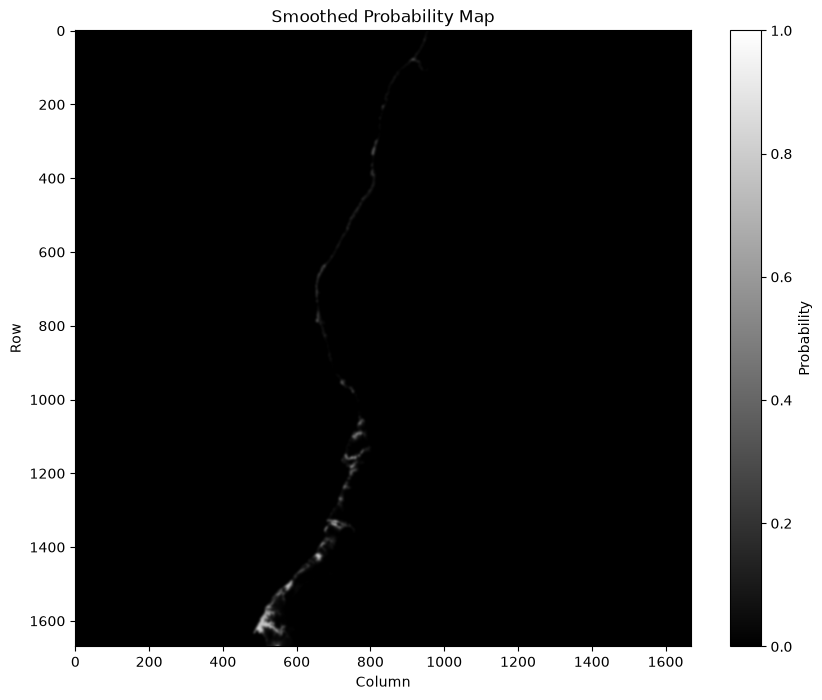

In [31]:
# smooth and without nan probability map
import numpy as np
import matplotlib.pyplot as plt

from osgeo import gdal
from skimage.filters import gaussian


# =========================================================
# 1. Read probability map
# =========================================================

file_name = "data/Delta_ClassProbability_tile_9.tif"

dataset = gdal.Open(file_name)

if dataset is None:
    raise FileNotFoundError(file_name)

probability = dataset.GetRasterBand(1).ReadAsArray().astype(float)


# =========================================================
# 2. Replace NaN with zero probability
# =========================================================

probability[np.isnan(probability)] = 0.0


# =========================================================
# 3. Smooth probability map
# =========================================================

probability_smooth = gaussian(
    probability,
    sigma=3,
    preserve_range=True,
)


# =========================================================
# 4. Plot smoothed probability map
# =========================================================

plt.figure(figsize=(10, 8))

plt.imshow(
    probability_smooth,
    cmap="gray",
    vmin=0,
    vmax=1,
)

plt.colorbar(label="Probability")

plt.xlabel("Column")
plt.ylabel("Row")
plt.title("Smoothed Probability Map")

plt.show()

center_row,center_col:  1400 700


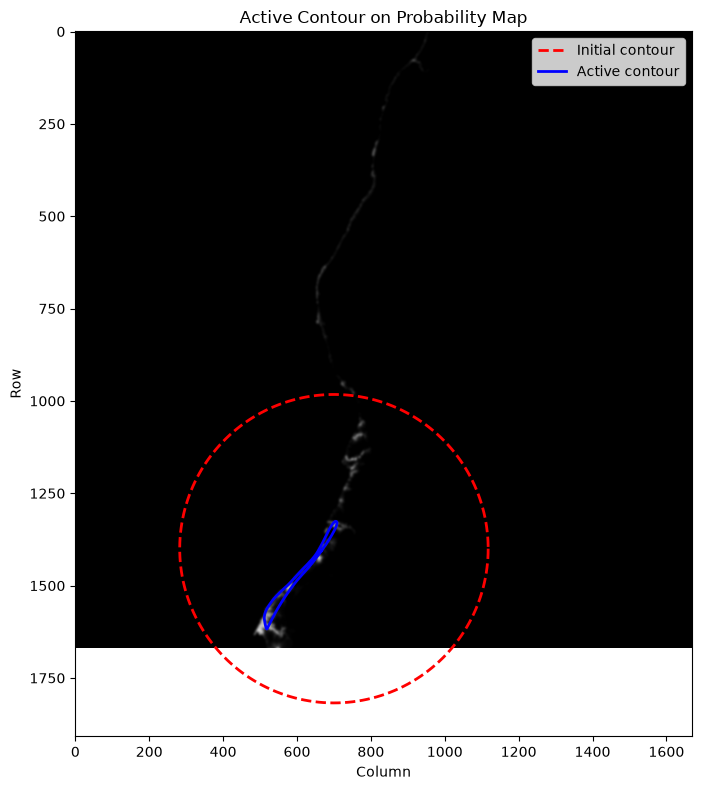

In [32]:
import numpy as np
import matplotlib.pyplot as plt

from osgeo import gdal
from skimage.filters import gaussian
from skimage.segmentation import active_contour


# =========================================================
# 1. Read probability map
# =========================================================

# file_name = "data/Delta_ClassProbability_tile_9.tif"

# dataset = gdal.Open(file_name)

# if dataset is None:
#     raise FileNotFoundError(f"Could not open: {file_name}")

# probability = dataset.GetRasterBand(1).ReadAsArray()

# print("Shape:", probability.shape)
# print("Data type:", probability.dtype)
# print("Minimum:", np.nanmin(probability))
# print("Maximum:", np.nanmax(probability))


# Convert to float
img = probability_smooth.astype(float)


# =========================================================
# 2. Smooth probability map
# =========================================================

img_smooth = gaussian(
    img,
    sigma=3,
    preserve_range=True,
)


# =========================================================
# 3. Define initial circular contour
# =========================================================

s = np.linspace(0, 2 * np.pi, 400)

# Change these values for your region
center_row = 1400  # img.shape[0] / 2
center_col = 700  # img.shape[1] / 2

print("center_row,center_col: ", center_row, center_col)

radius = min(img.shape) * 0.25

r = center_row + radius * np.sin(s)
c = center_col + radius * np.cos(s)

init = np.column_stack((r, c))


# =========================================================
# 4. Run active contour
# =========================================================

snake = active_contour(
    img_smooth,
    init,
    alpha=0.015,
    beta=10,
    gamma=0.001,
)


# =========================================================
# 5. Plot
# =========================================================

fig, ax = plt.subplots(figsize=(8, 8))

ax.imshow(
    img,
    cmap="gray",
    vmin=0,
    vmax=1,
)

ax.plot(
    init[:, 1],
    init[:, 0],
    "--r",
    linewidth=2,
    label="Initial contour",
)

ax.plot(
    snake[:, 1],
    snake[:, 0],
    "-b",
    linewidth=2,
    label="Active contour",
)

ax.set_title("Active Contour on Probability Map")
ax.set_xlabel("Column")
ax.set_ylabel("Row")
ax.legend()

plt.tight_layout()
plt.show()

center_row,center_col:  1550 500


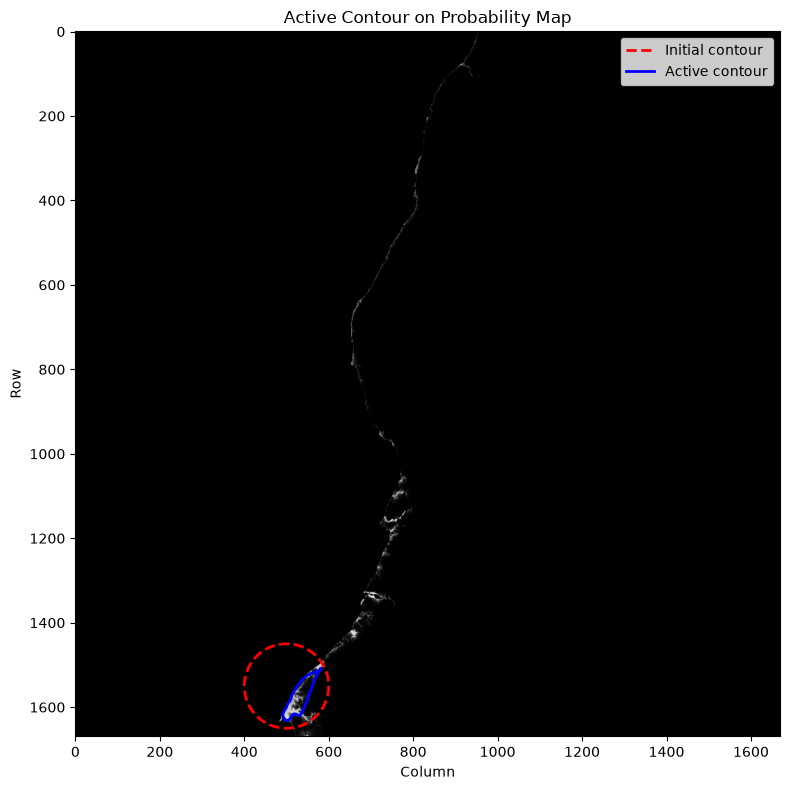

In [34]:
import numpy as np
import matplotlib.pyplot as plt

from osgeo import gdal
from skimage.filters import gaussian
from skimage.segmentation import active_contour


# =========================================================
# 1. Read probability map
# =========================================================

# file_name = "data/Delta_ClassProbability_tile_9.tif"

# dataset = gdal.Open(file_name)

# if dataset is None:
#     raise FileNotFoundError(f"Could not open: {file_name}")

# probability = dataset.GetRasterBand(1).ReadAsArray()

# print("Shape:", probability.shape)
# print("Data type:", probability.dtype)
# print("Minimum:", np.nanmin(probability))
# print("Maximum:", np.nanmax(probability))


# Convert to float
img = probability_without_nan.astype(float)


# =========================================================
# 2. Smooth probability map
# =========================================================

img_smooth = gaussian(
    img,
    sigma=3,
    preserve_range=True,
)


# =========================================================
# 3. Define initial circular contour
# =========================================================

s = np.linspace(0, 2 * np.pi, 400)

# Change these values for your region
center_row = 1550  # img.shape[0] / 2
center_col = 500  # img.shape[1] / 2

print("center_row,center_col: ", center_row, center_col)

radius = 100  # min(img.shape) * 0.25

r = center_row + radius * np.sin(s)
c = center_col + radius * np.cos(s)

init = np.column_stack((r, c))


# =========================================================
# 4. Run active contour
# =========================================================

snake = active_contour(
    img_smooth,
    init,
    alpha=0.015,
    beta=10,
    gamma=0.001,
)


# =========================================================
# 5. Plot
# =========================================================

fig, ax = plt.subplots(figsize=(8, 8))

ax.imshow(
    img,
    cmap="gray",
    vmin=0,
    vmax=1,
)

ax.plot(
    init[:, 1],
    init[:, 0],
    "--r",
    linewidth=2,
    label="Initial contour",
)

ax.plot(
    snake[:, 1],
    snake[:, 0],
    "-b",
    linewidth=2,
    label="Active contour",
)

ax.set_title("Active Contour on Probability Map")
ax.set_xlabel("Column")
ax.set_ylabel("Row")
ax.legend()

plt.tight_layout()
plt.show()

center_row,center_col:  1550 500


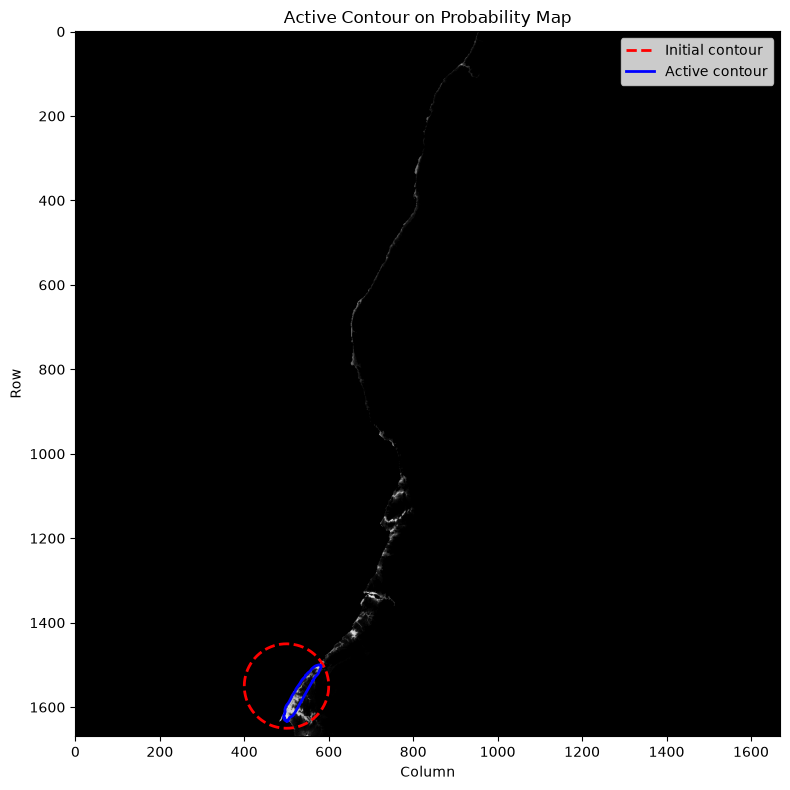

In [50]:
import numpy as np
import matplotlib.pyplot as plt

from osgeo import gdal
from skimage.filters import gaussian
from skimage.segmentation import active_contour


# =========================================================
# 1. Read probability map
# =========================================================

# file_name = "data/Delta_ClassProbability_tile_9.tif"

# dataset = gdal.Open(file_name)

# if dataset is None:
#     raise FileNotFoundError(f"Could not open: {file_name}")

# probability = dataset.GetRasterBand(1).ReadAsArray()

# print("Shape:", probability.shape)
# print("Data type:", probability.dtype)
# print("Minimum:", np.nanmin(probability))
# print("Maximum:", np.nanmax(probability))


# Convert to float
img = probability_without_nan.astype(float)


# =========================================================
# 2. Smooth probability map
# =========================================================

img_smooth = gaussian(
    img,
    sigma=3,
    preserve_range=True,
)


# =========================================================
# 3. Define initial circular contour
# =========================================================

s = np.linspace(0, 2 * np.pi, 400)

# Change these values for your region
center_row = 1550  # img.shape[0] / 2
center_col = 500  # img.shape[1] / 2

print("center_row,center_col: ", center_row, center_col)

radius = 100  # min(img.shape) * 0.25

r = center_row + radius * np.sin(s)
c = center_col + radius * np.cos(s)

init = np.column_stack((r, c))


# =========================================================
# 4. Run active contour
# =========================================================

snake = active_contour(
    img_smooth,
    init,
    alpha=0.00015,
    beta=100,
    gamma=0.0001,
)


# =========================================================
# 5. Plot
# =========================================================

fig, ax = plt.subplots(figsize=(8, 8))

ax.imshow(
    img,
    cmap="gray",
    vmin=0,
    vmax=1,
)

ax.plot(
    init[:, 1],
    init[:, 0],
    "--r",
    linewidth=2,
    label="Initial contour",
)

ax.plot(
    snake[:, 1],
    snake[:, 0],
    "-b",
    linewidth=2,
    label="Active contour",
)

ax.set_title("Active Contour on Probability Map")
ax.set_xlabel("Column")
ax.set_ylabel("Row")
ax.legend()

plt.tight_layout()
plt.show()

## 2. edge + contour line

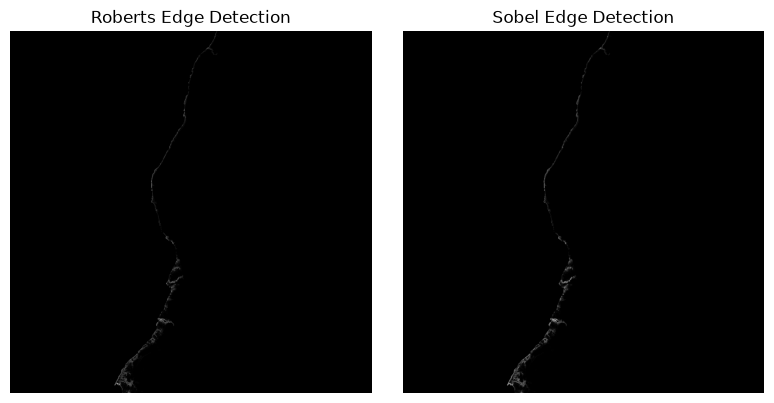

In [36]:
import numpy as np
import matplotlib.pyplot as plt

from skimage import filters
from skimage.data import camera
from skimage.util import compare_images


image = probability_without_nan
edge_roberts = filters.roberts(image)
edge_sobel = filters.sobel(image)

fig, axes = plt.subplots(ncols=2, sharex=True, sharey=True, figsize=(8, 4))

axes[0].imshow(edge_roberts, cmap=plt.cm.gray)
axes[0].set_title("Roberts Edge Detection")

axes[1].imshow(edge_sobel, cmap=plt.cm.gray)
axes[1].set_title("Sobel Edge Detection")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

Number of contours: 743
Contour 0: 170 points
Contour 1: 5 points
Contour 2: 5 points
Contour 3: 5 points
Contour 4: 5 points
Contour 5: 5 points
Contour 6: 9 points
Contour 7: 5 points
Contour 8: 5 points
Contour 9: 247 points
Contour 10: 5 points
Contour 11: 5 points
Contour 12: 13 points
Contour 13: 5 points
Contour 14: 5 points
Contour 15: 5 points
Contour 16: 5 points
Contour 17: 7 points
Contour 18: 11 points
Contour 19: 5 points
Contour 20: 5 points
Contour 21: 5 points
Contour 22: 51 points
Contour 23: 9 points
Contour 24: 5 points
Contour 25: 11 points
Contour 26: 5 points
Contour 27: 7 points
Contour 28: 5 points
Contour 29: 37 points
Contour 30: 49 points
Contour 31: 5 points
Contour 32: 5 points
Contour 33: 15 points
Contour 34: 13 points
Contour 35: 5 points
Contour 36: 5 points
Contour 37: 19 points
Contour 38: 5 points
Contour 39: 5 points
Contour 40: 5 points
Contour 41: 5 points
Contour 42: 5 points
Contour 43: 17 points
Contour 44: 5 points
Contour 45: 5 points
Contou

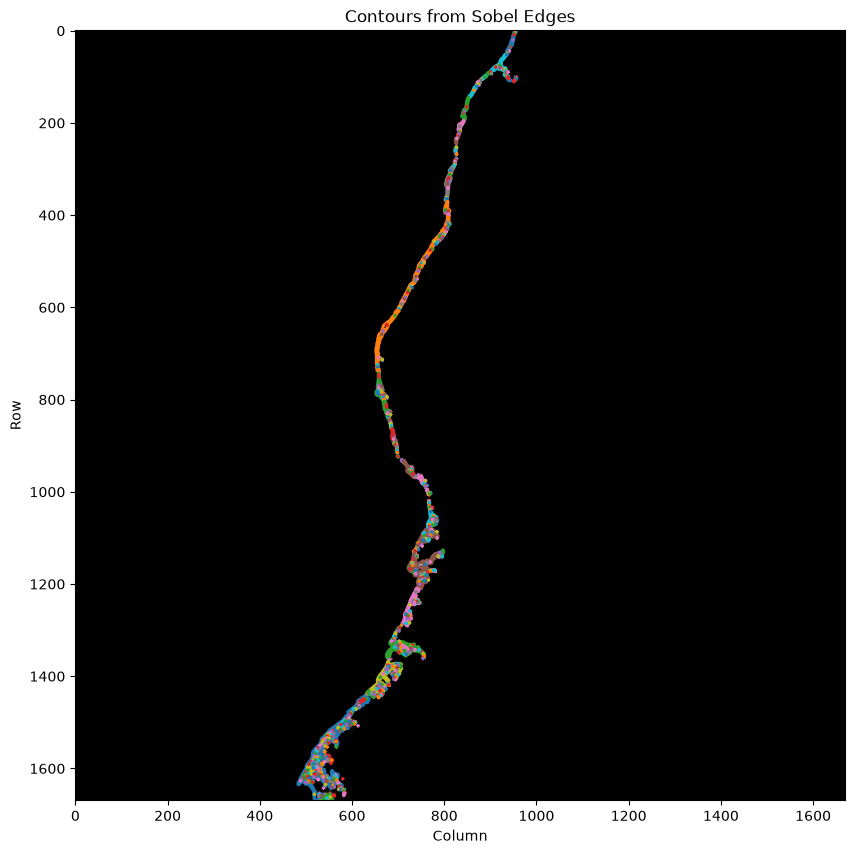

In [37]:
from skimage import filters
from skimage.measure import find_contours
import matplotlib.pyplot as plt

image = probability

edge_sobel = filters.sobel(image)

threshold = 0.05
edge_mask = edge_sobel > threshold

contours = find_contours(
    edge_mask.astype(float),
    level=0.5,
)

print("Number of contours:", len(contours))

for i, contour in enumerate(contours):
    print(f"Contour {i}: {len(contour)} points")

plt.figure(figsize=(10, 10))

plt.imshow(
    image,
    cmap="gray",
    vmin=0,
    vmax=1,
)

for contour in contours:
    plt.plot(
        contour[:, 1],
        contour[:, 0],
        linewidth=2,
    )

plt.title("Contours from Sobel Edges")
plt.xlabel("Column")
plt.ylabel("Row")

plt.show()

Number of polygon points: 1479


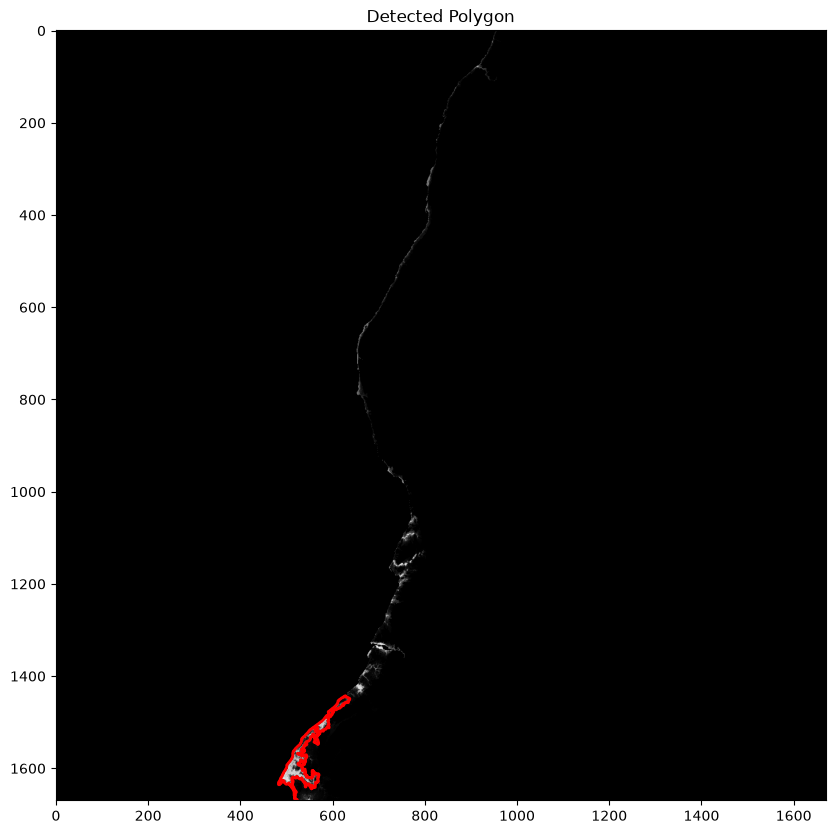

In [ ]:
largest_contour = max(
    contours,
    key=len,
)

print("Number of polygon points:", len(largest_contour))

polygon_y = largest_contour[:, 0]  # row
polygon_x = largest_contour[:, 1]  # column

plt.figure(figsize=(10, 10))

plt.imshow(
    image,
    cmap="gray",
    vmin=0,
    vmax=1,
)

plt.plot(
    polygon_x,
    polygon_y,
    "-r",
    linewidth=2,
)

plt.title("Detected Polygon")
plt.show()

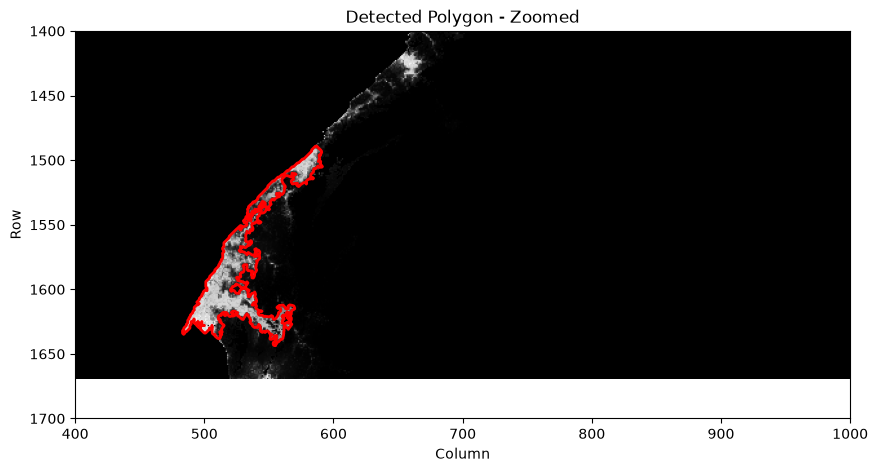

In [54]:
plt.figure(figsize=(10, 10))

plt.imshow(
    image,
    cmap="gray",
    vmin=0,
    vmax=1,
)

plt.plot(
    polygon_x,
    polygon_y,
    "-r",
    linewidth=2,
)

# Zoom region
plt.xlim(400, 1000)  # columns
plt.ylim(1700, 1400)  # rows (reversed for images)

plt.title("Detected Polygon - Zoomed")
plt.xlabel("Column")
plt.ylabel("Row")

plt.show()

Shape: (1670, 1670)
Minimum: 0.0011258919945991046
Maximum: 0.9575190702272284
Number of NaN pixels: 2764382
NaN in smoothed map: 0
Number of contours: 6
Contour 0: 15 points
Contour 1: 31 points
Contour 2: 55 points
Contour 3: 63 points
Contour 4: 243 points
Contour 5: 4 points
Selected polygon points: 243


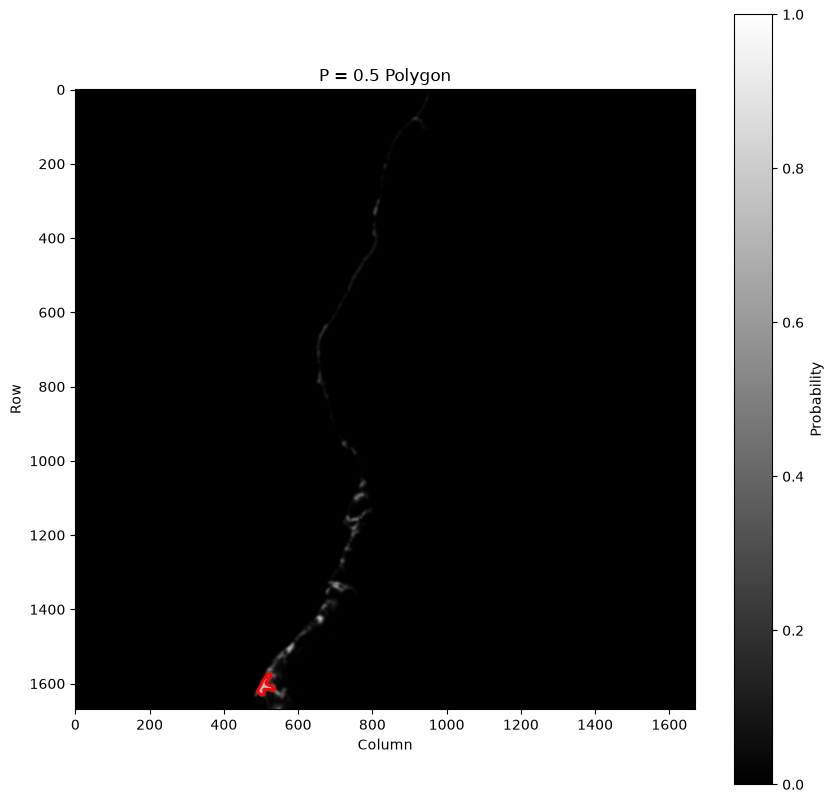

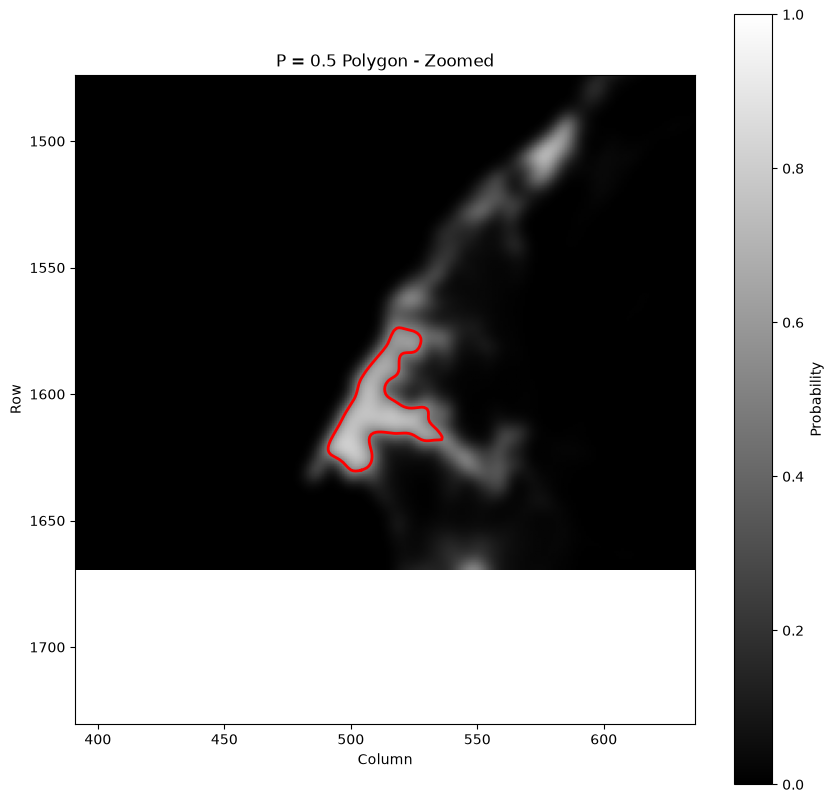

In [41]:
import numpy as np
import matplotlib.pyplot as plt

from osgeo import gdal
from skimage.filters import gaussian
from skimage.measure import find_contours


# =========================================================
# 1. Read probability map
# =========================================================

file_name = "data/Delta_ClassProbability_tile_9.tif"

dataset = gdal.Open(file_name)

if dataset is None:
    raise FileNotFoundError(f"Could not open: {file_name}")

probability = dataset.GetRasterBand(1).ReadAsArray().astype(float)

print("Shape:", probability.shape)
print("Minimum:", np.nanmin(probability))
print("Maximum:", np.nanmax(probability))
print("Number of NaN pixels:", np.isnan(probability).sum())


# =========================================================
# 2. Replace NaN with zero probability
# =========================================================

probability_without_nan = probability.copy()

probability_without_nan[np.isnan(probability_without_nan)] = 0.0


# =========================================================
# 3. Smooth probability map
# =========================================================

probability_smooth_without_nan = gaussian(
    probability_without_nan,
    sigma=3,
    preserve_range=True,
)

print(
    "NaN in smoothed map:",
    np.isnan(probability_smooth_without_nan).sum(),
)


# =========================================================
# 4. Find P = 0.5 contours
# =========================================================

level = 0.5

contours = find_contours(
    probability_smooth_without_nan,
    level=level,
)

print("Number of contours:", len(contours))

for i, contour in enumerate(contours):
    print(f"Contour {i}: {len(contour)} points")


# =========================================================
# 5. Select the largest contour
# =========================================================

if len(contours) == 0:
    raise RuntimeError(f"No contour found at probability level {level}")

polygon = max(
    contours,
    key=len,
)

# find_contours returns:
# polygon[:, 0] -> row
# polygon[:, 1] -> column

polygon_y = polygon[:, 0]
polygon_x = polygon[:, 1]

print("Selected polygon points:", len(polygon))


# =========================================================
# 6. Plot full map and polygon
# =========================================================

plt.figure(figsize=(10, 10))

plt.imshow(
    probability_smooth_without_nan,
    cmap="gray",
    vmin=0,
    vmax=1,
)

plt.plot(
    polygon_x,
    polygon_y,
    "-r",
    linewidth=2,
)

plt.colorbar(label="Probability")

plt.title("P = 0.5 Polygon")
plt.xlabel("Column")
plt.ylabel("Row")

plt.show()


# =========================================================
# 7. Zoom automatically around polygon
# =========================================================

margin = 100

xmin = polygon_x.min() - margin
xmax = polygon_x.max() + margin

ymin = polygon_y.min() - margin
ymax = polygon_y.max() + margin

plt.figure(figsize=(10, 10))

plt.imshow(
    probability_smooth_without_nan,
    cmap="gray",
    vmin=0,
    vmax=1,
)

plt.plot(
    polygon_x,
    polygon_y,
    "-r",
    linewidth=2,
)

plt.xlim(xmin, xmax)
plt.ylim(ymax, ymin)

plt.colorbar(label="Probability")

plt.title("P = 0.5 Polygon - Zoomed")
plt.xlabel("Column")
plt.ylabel("Row")

plt.show()

# 2.2. contour line for map its nan is replaced with 0

Shape: (1670, 1670)
Minimum: 0.0011258919945991046
Maximum: 0.9575190702272284
Number of NaN pixels: 2764382
Number of contours: 699
Contour 0: 7 points
Contour 1: 5 points
Contour 2: 7 points
Contour 3: 11 points
Contour 4: 5 points
Contour 5: 13 points
Contour 6: 5 points
Contour 7: 11 points
Contour 8: 11 points
Contour 9: 41 points
Contour 10: 5 points
Contour 11: 5 points
Contour 12: 5 points
Contour 13: 5 points
Contour 14: 13 points
Contour 15: 9 points
Contour 16: 5 points
Contour 17: 9 points
Contour 18: 9 points
Contour 19: 5 points
Contour 20: 5 points
Contour 21: 15 points
Contour 22: 11 points
Contour 23: 5 points
Contour 24: 17 points
Contour 25: 149 points
Contour 26: 5 points
Contour 27: 5 points
Contour 28: 5 points
Contour 29: 5 points
Contour 30: 5 points
Contour 31: 5 points
Contour 32: 5 points
Contour 33: 5 points
Contour 34: 5 points
Contour 35: 5 points
Contour 36: 5 points
Contour 37: 7 points
Contour 38: 5 points
Contour 39: 5 points
Contour 40: 17 points
Cont

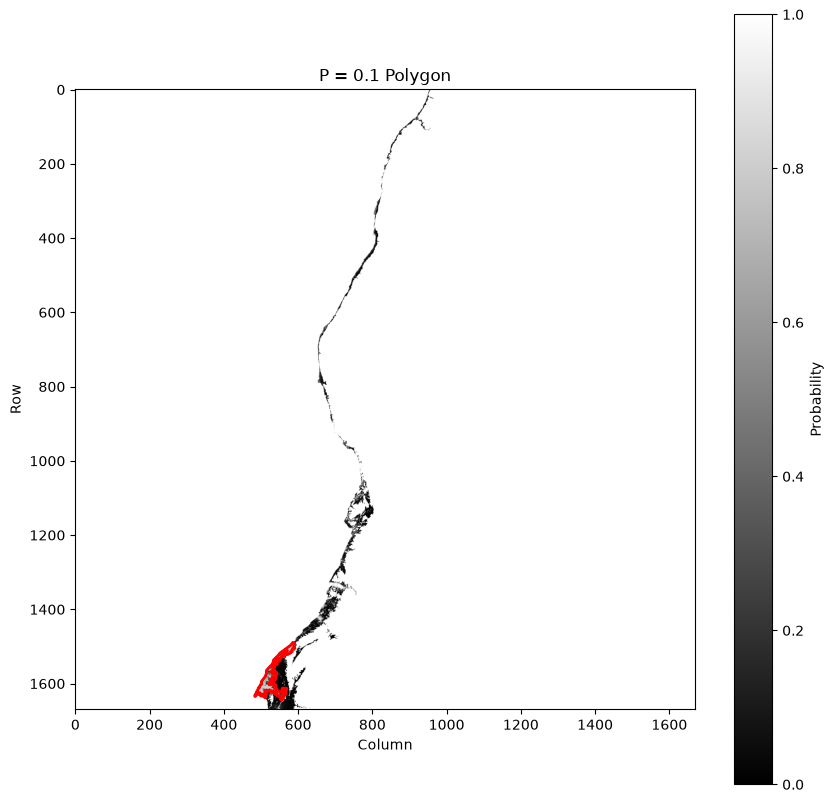

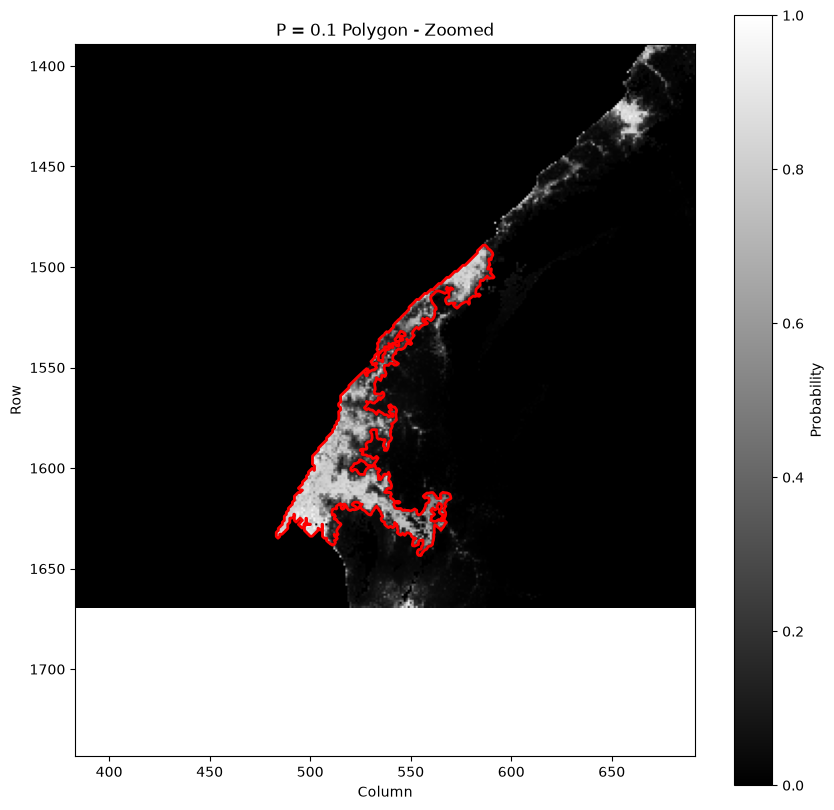

In [60]:
import numpy as np
import matplotlib.pyplot as plt

from osgeo import gdal
from skimage.filters import gaussian
from skimage.measure import find_contours


# =========================================================
# 1. Read probability map
# =========================================================

file_name = "data/Delta_ClassProbability_tile_9.tif"

dataset = gdal.Open(file_name)

if dataset is None:
    raise FileNotFoundError(f"Could not open: {file_name}")

probability = dataset.GetRasterBand(1).ReadAsArray().astype(float)

print("Shape:", probability.shape)
print("Minimum:", np.nanmin(probability))
print("Maximum:", np.nanmax(probability))
print("Number of NaN pixels:", np.isnan(probability).sum())


# # =========================================================
# # 2. Replace NaN with zero probability
# # =========================================================

probability_without_nan = probability.copy()

probability_without_nan[np.isnan(probability_without_nan)] = 0.0


# # =========================================================
# # 3. Smooth probability map
# # =========================================================

# probability_smooth_without_nan = gaussian(
#     probability_without_nan,
#     sigma=3,
#     preserve_range=True,
# )

# print(
#     "NaN in smoothed map:",
#     np.isnan(probability_smooth_without_nan).sum(),
# )


# =========================================================
# 4. Find P = 0.5 contours
# =========================================================

level = 0.1

contours = find_contours(
    probability_without_nan,
    level=level,
)

print("Number of contours:", len(contours))

for i, contour in enumerate(contours):
    print(f"Contour {i}: {len(contour)} points")


# =========================================================
# 5. Select the largest contour
# =========================================================

if len(contours) == 0:
    raise RuntimeError(f"No contour found at probability level {level}")

polygon = max(
    contours,
    key=len,
)

# find_contours returns:
# polygon[:, 0] -> row
# polygon[:, 1] -> column

polygon_y = polygon[:, 0]
polygon_x = polygon[:, 1]

print("Selected polygon points:", len(polygon))


# =========================================================
# 6. Plot full map and polygon
# =========================================================

plt.figure(figsize=(10, 10))

plt.imshow(
    probability,
    cmap="gray",
    vmin=0,
    vmax=1,
)

plt.plot(
    polygon_x,
    polygon_y,
    "-r",
    linewidth=2,
)

plt.colorbar(label="Probability")

plt.title(f"P = {level} Polygon")
plt.xlabel("Column")
plt.ylabel("Row")

plt.show()


# =========================================================
# 7. Zoom automatically around polygon
# =========================================================

margin = 100

xmin = polygon_x.min() - margin
xmax = polygon_x.max() + margin

ymin = polygon_y.min() - margin
ymax = polygon_y.max() + margin

plt.figure(figsize=(10, 10))

plt.imshow(
    probability_without_nan,
    cmap="gray",
    vmin=0,
    vmax=1,
)

plt.plot(
    polygon_x,
    polygon_y,
    "-r",
    linewidth=2,
)

plt.xlim(xmin, xmax)
plt.ylim(ymax, ymin)

plt.colorbar(label="Probability")

plt.title(f"P = {level} Polygon - Zoomed")
plt.xlabel("Column")
plt.ylabel("Row")

plt.show()


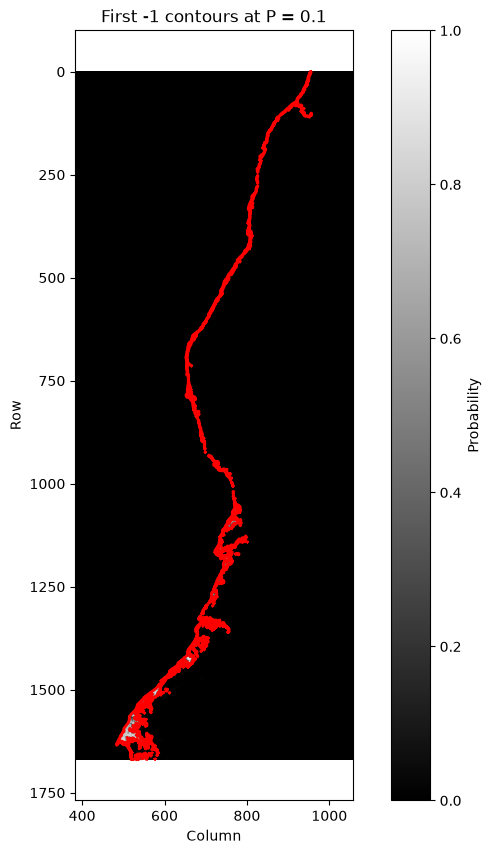

In [81]:
n_contours_to_plot = -1  # 500

# Select the first N contours
contours_to_plot = contours[:n_contours_to_plot]

plt.figure(figsize=(10, 10))

plt.imshow(
    probability_without_nan,
    cmap="gray",
    vmin=0,
    vmax=1,
)

# Plot the selected contours
for contour in contours_to_plot:
    contour_y = contour[:, 0]
    contour_x = contour[:, 1]

    plt.plot(
        contour_x,
        contour_y,
        "-r",
        linewidth=2,
    )

# Set limits based on the selected contours
all_points = np.vstack(contours_to_plot)

xmin = all_points[:, 1].min() - margin
xmax = all_points[:, 1].max() + margin

ymin = all_points[:, 0].min() - margin
ymax = all_points[:, 0].max() + margin

plt.xlim(xmin, xmax)
plt.ylim(ymax, ymin)

plt.colorbar(label="Probability")

plt.title(f"First {min(n_contours_to_plot, len(contours))} contours at P = {level}")

plt.xlabel("Column")
plt.ylabel("Row")

plt.show()

LineString length: 999.4933030461278
LineString is simple: True


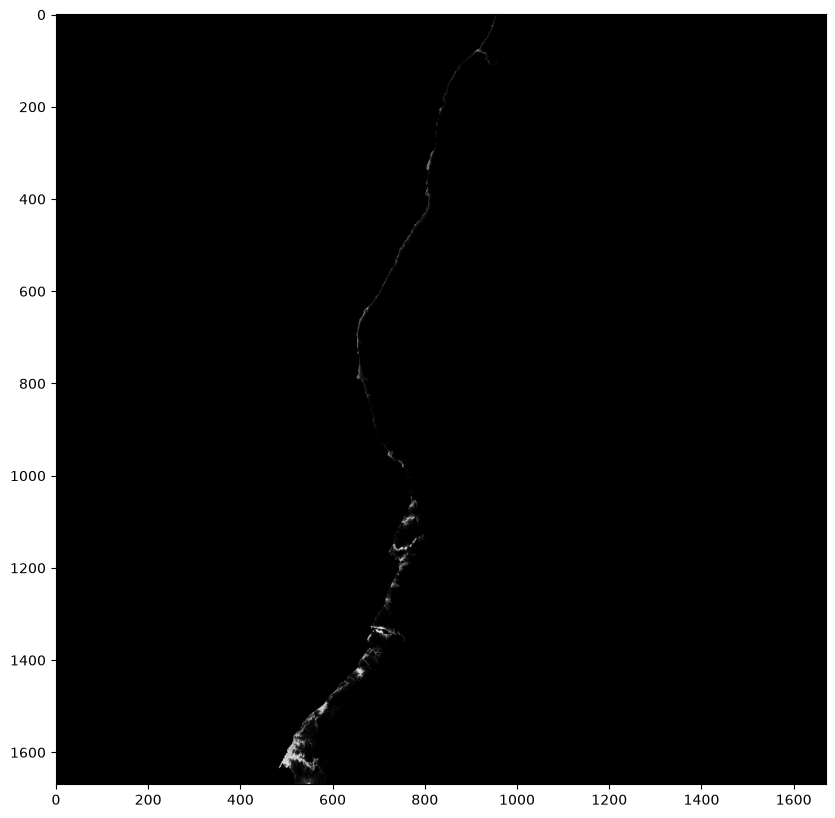

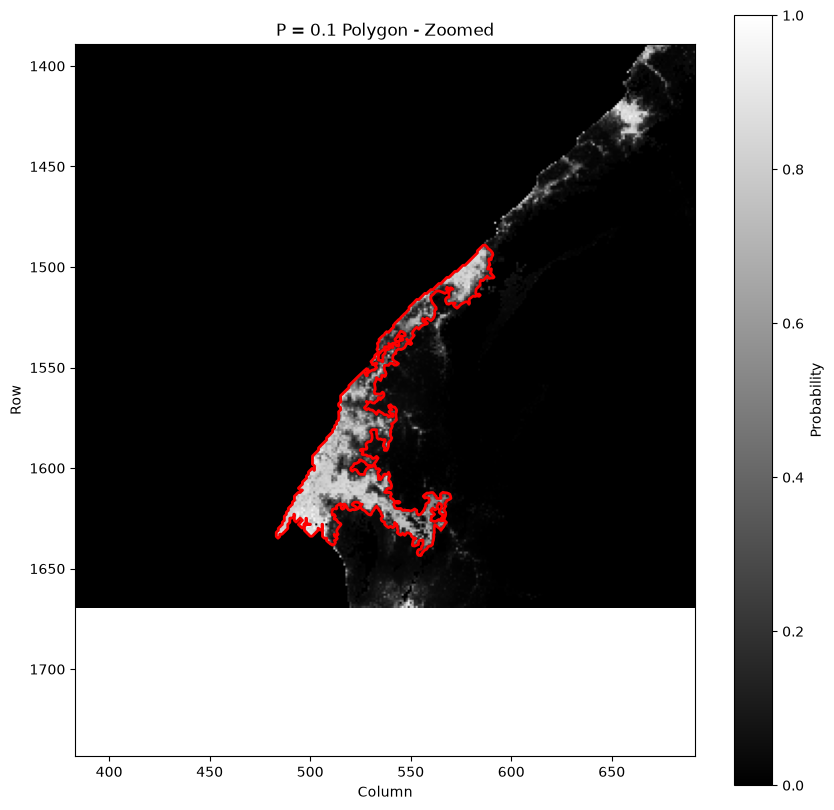

Text(0, 0.5, 'Row')

<Figure size 1000x1000 with 0 Axes>

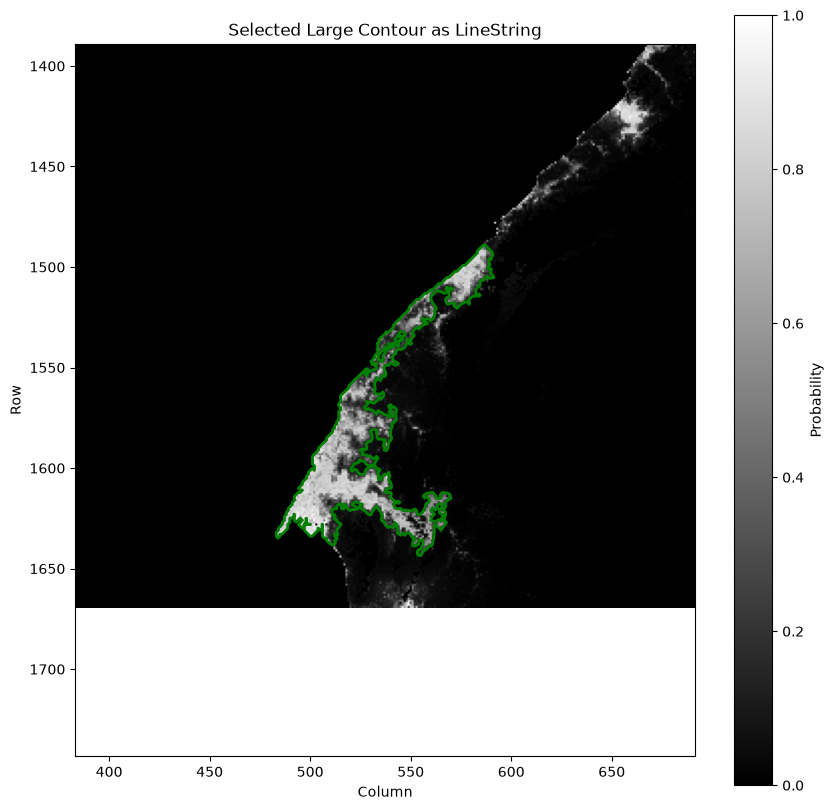

In [72]:
from shapely.geometry import LineString

# =========================================================
# 6. Create LineString from the selected contour
# =========================================================

line = LineString(
    np.column_stack(
        [
            polygon_x,  # x
            polygon_y,  # y
        ]
    )
)

print("LineString length:", line.length)
print("LineString is simple:", line.is_simple)


# =========================================================
# 7. Plot selected large contour
# =========================================================

plt.figure(figsize=(10, 10))

plt.imshow(
    probability_without_nan,
    cmap="gray",
    vmin=0,
    vmax=1,
)

margin = 100

xmin = polygon_x.min() - margin
xmax = polygon_x.max() + margin

ymin = polygon_y.min() - margin
ymax = polygon_y.max() + margin

plt.figure(figsize=(10, 10))

plt.imshow(
    probability_without_nan,
    cmap="gray",
    vmin=0,
    vmax=1,
)

plt.plot(
    polygon_x,
    polygon_y,
    "-r",
    linewidth=2,
)

plt.xlim(xmin, xmax)
plt.ylim(ymax, ymin)

plt.colorbar(label="Probability")

plt.title(f"P = {level} Polygon - Zoomed")
plt.xlabel("Column")
plt.ylabel("Row")

plt.show()


line_x, line_y = line.xy

plt.figure(figsize=(10, 10))

margin = 100

xmin = polygon_x.min() - margin
xmax = polygon_x.max() + margin

ymin = polygon_y.min() - margin
ymax = polygon_y.max() + margin

plt.figure(figsize=(10, 10))

plt.imshow(
    probability_without_nan,
    cmap="gray",
    vmin=0,
    vmax=1,
)

plt.plot(
    line_x,
    line_y,
    "-g",
    linewidth=2,
)

plt.xlim(xmin, xmax)
plt.ylim(ymax, ymin)

plt.colorbar(label="Probability")


plt.title("Selected Large Contour as LineString")
plt.xlabel("Column")
plt.ylabel("Row")

LineString length: 999.4933030461278
LineString is simple: True
Noded geometry type: LineString
Number of polygons: 1
Polygon 0: area = 3473.45
Selected polygon area: 3473.4498152158917
Selected polygon valid: True


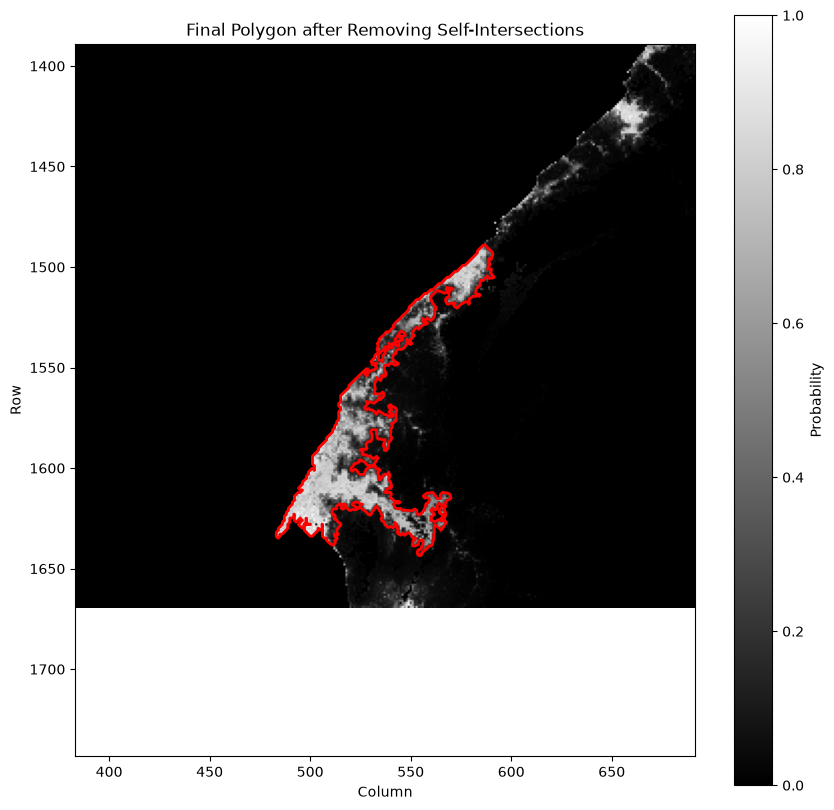

In [74]:
from shapely.geometry import LineString, Polygon
from shapely.ops import unary_union, polygonize

# =========================================================
# 6. Create LineString from the selected contour
# =========================================================

line = LineString(
    np.column_stack(
        [
            polygon_x,
            polygon_y,
        ]
    )
)

print("LineString length:", line.length)
print("LineString is simple:", line.is_simple)


# =========================================================
# 7. Split the LineString at self-intersections
# =========================================================

noded_line = unary_union(line)

print("Noded geometry type:", noded_line.geom_type)


# =========================================================
# 8. Create polygons from the resulting line segments
# =========================================================

polygons = list(polygonize(noded_line))

print("Number of polygons:", len(polygons))

for i, poly in enumerate(polygons):
    print(f"Polygon {i}: area = {poly.area:.2f}")


# =========================================================
# 9. Select the largest polygon
# =========================================================

if len(polygons) == 0:
    raise RuntimeError("No polygon could be created from the contour.")

polygon = max(
    polygons,
    key=lambda poly: poly.area,
)

print("Selected polygon area:", polygon.area)
print("Selected polygon valid:", polygon.is_valid)

# =========================================================
# 10. Plot the final polygon
# =========================================================

polygon_x_plot, polygon_y_plot = polygon.exterior.xy

plt.figure(figsize=(10, 10))

plt.imshow(
    probability_without_nan,
    cmap="gray",
    vmin=0,
    vmax=1,
)

plt.plot(
    polygon_x_plot,
    polygon_y_plot,
    "-r",
    linewidth=2,
)

plt.xlim(xmin, xmax)
plt.ylim(ymax, ymin)

plt.colorbar(label="Probability")

plt.title("Final Polygon after Removing Self-Intersections")
plt.xlabel("Column")
plt.ylabel("Row")

plt.show()

Number of vertices: 1299
LineString type: LineString
LineString length: 999.4933030461278
LineString is simple: True
LineString is closed: True

Polygon information
-------------------
Geometry type: Polygon
Number of vertices: 1299
Area: 3473.4498152158894
Is valid: True
Is simple: True


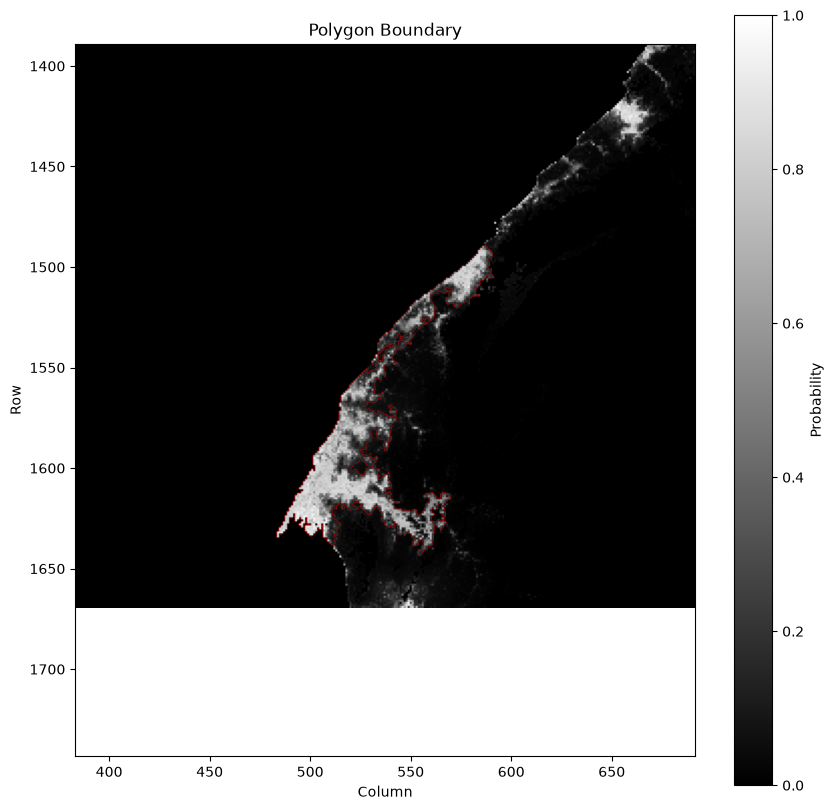

In [76]:
import numpy as np
import matplotlib.pyplot as plt

from shapely.geometry import LineString, Polygon
from shapely.validation import explain_validity


# =========================================================
# 1. Create LineString from selected contour
# =========================================================

coordinates = np.column_stack(
    [
        polygon_x,
        polygon_y,
    ]
)

line = LineString(coordinates)


# =========================================================
# 2. Check the contour
# =========================================================

print("Number of vertices:", len(coordinates))
print("LineString type:", line.geom_type)
print("LineString length:", line.length)
print("LineString is simple:", line.is_simple)
print("LineString is closed:", line.is_ring)


# =========================================================
# 3. Create Polygon directly from contour
# =========================================================

polygon = Polygon(coordinates)


# =========================================================
# 4. Check the polygon
# =========================================================

print("\nPolygon information")
print("-------------------")
print("Geometry type:", polygon.geom_type)
print("Number of vertices:", len(polygon.exterior.coords))
print("Area:", polygon.area)
print("Is valid:", polygon.is_valid)
print("Is simple:", polygon.boundary.is_simple)

if not polygon.is_valid:
    print("Invalid reason:")
    print(explain_validity(polygon))


# =========================================================
# 5. Plot the polygon boundary
# =========================================================

polygon_x_plot, polygon_y_plot = polygon.exterior.xy

plt.figure(figsize=(10, 10))

plt.imshow(
    probability_without_nan,
    cmap="gray",
    vmin=0,
    vmax=1,
)

plt.plot(
    polygon_x_plot,
    polygon_y_plot,
    "-r",
    linewidth=0.25,
)

plt.xlim(xmin, xmax)
plt.ylim(ymax, ymin)

plt.colorbar(label="Probability")

plt.title("Polygon Boundary")
plt.xlabel("Column")
plt.ylabel("Row")

plt.show()

# Appendix

center_row,center_col:  1400 700


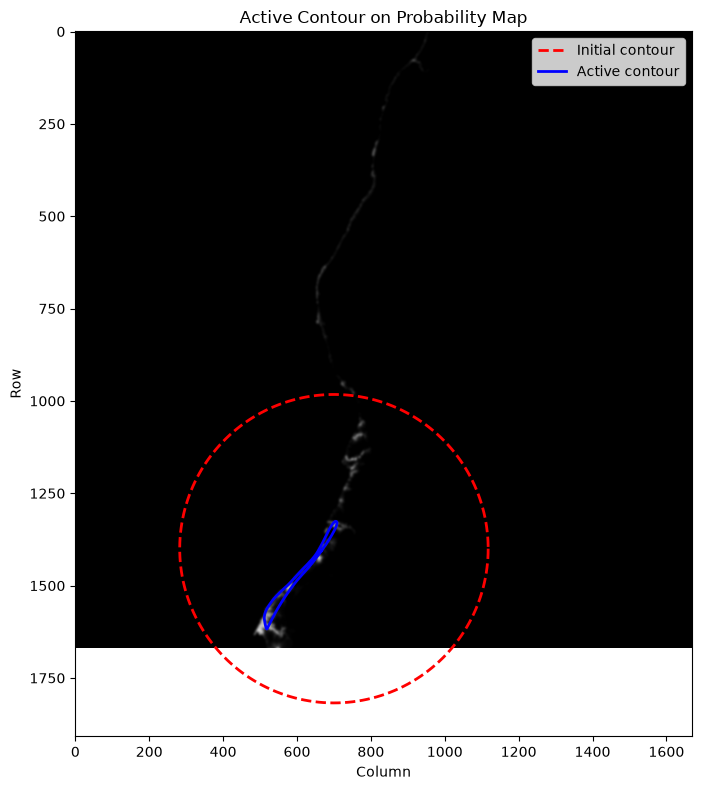

In [73]:
import numpy as np
import matplotlib.pyplot as plt

from osgeo import gdal
from skimage.filters import gaussian
from skimage.segmentation import active_contour


# =========================================================
# 1. Read probability map
# =========================================================

# file_name = "data/Delta_ClassProbability_tile_9.tif"

# dataset = gdal.Open(file_name)

# if dataset is None:
#     raise FileNotFoundError(f"Could not open: {file_name}")

# probability = dataset.GetRasterBand(1).ReadAsArray()

# print("Shape:", probability.shape)
# print("Data type:", probability.dtype)
# print("Minimum:", np.nanmin(probability))
# print("Maximum:", np.nanmax(probability))


# Convert to float
img = probability_smooth.astype(float)


# =========================================================
# 2. Smooth probability map
# =========================================================

img_smooth = gaussian(
    img,
    sigma=3,
    preserve_range=True,
)


# =========================================================
# 3. Define initial circular contour
# =========================================================

s = np.linspace(0, 2 * np.pi, 400)

# Change these values for your region
center_row = 1400  # img.shape[0] / 2
center_col = 700  # img.shape[1] / 2

print("center_row,center_col: ", center_row, center_col)

radius = min(img.shape) * 0.25

r = center_row + radius * np.sin(s)
c = center_col + radius * np.cos(s)

init = np.column_stack((r, c))


# =========================================================
# 4. Run active contour
# =========================================================

snake = active_contour(
    img_smooth,
    init,
    alpha=0.015,
    beta=10,
    gamma=0.001,
)


# =========================================================
# 5. Plot
# =========================================================

fig, ax = plt.subplots(figsize=(8, 8))

ax.imshow(
    img,
    cmap="gray",
    vmin=0,
    vmax=1,
)

ax.plot(
    init[:, 1],
    init[:, 0],
    "--r",
    linewidth=2,
    label="Initial contour",
)

ax.plot(
    snake[:, 1],
    snake[:, 0],
    "-b",
    linewidth=2,
    label="Active contour",
)

ax.set_title("Active Contour on Probability Map")
ax.set_xlabel("Column")
ax.set_ylabel("Row")
ax.legend()

plt.tight_layout()
plt.show()

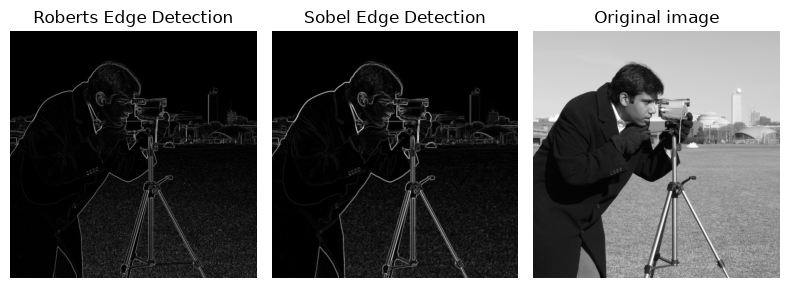

In [83]:
import numpy as np
import matplotlib.pyplot as plt

from skimage import filters
from skimage.data import camera
from skimage.util import compare_images


image = camera()
edge_roberts = filters.roberts(image)
edge_sobel = filters.sobel(image)

fig, axes = plt.subplots(ncols=3, sharex=True, sharey=True, figsize=(8, 4))

axes[0].imshow(edge_roberts, cmap=plt.cm.gray)
axes[0].set_title("Roberts Edge Detection")

axes[1].imshow(edge_sobel, cmap=plt.cm.gray)
axes[1].set_title("Sobel Edge Detection")

axes[2].imshow(image, cmap=plt.cm.gray)
axes[2].set_title("Original image")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

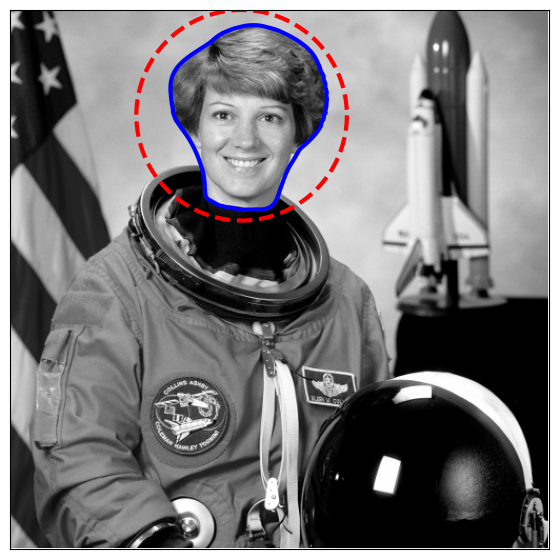

In [30]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.color import rgb2gray
from skimage import data
from skimage.filters import gaussian
from skimage.segmentation import active_contour


img = data.astronaut()
img = rgb2gray(img)

s = np.linspace(0, 2 * np.pi, 400)
r = 100 + 100 * np.sin(s)
c = 220 + 100 * np.cos(s)
init = np.array([r, c]).T

snake = active_contour(
    gaussian(img, sigma=3, preserve_range=False),
    init,
    alpha=0.015,
    beta=10,
    gamma=0.001,
)

fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(img, cmap=plt.cm.gray)
ax.plot(init[:, 1], init[:, 0], "--r", lw=3)
ax.plot(snake[:, 1], snake[:, 0], "-b", lw=3)
ax.set_xticks([]), ax.set_yticks([])
ax.axis([0, img.shape[1], img.shape[0], 0])

plt.show()

Here we initialize a straight line between two points, `(5, 136)` and
`(424, 50)`, and require that the spline has its end points there by giving
the boundary condition `boundary_condition='fixed'`. We furthermore
make the algorithm search for dark lines by giving a negative `w_line` value.



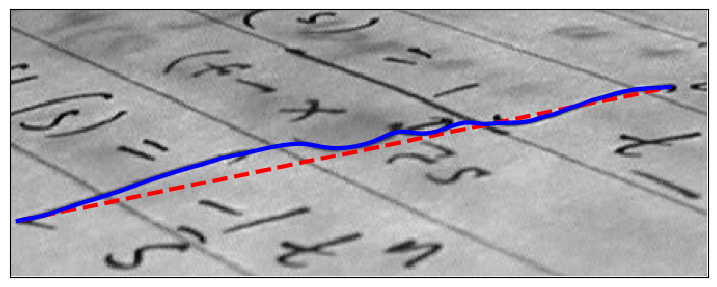

In [13]:
img = data.text()

r = np.linspace(136, 50, 100)
c = np.linspace(5, 424, 100)
init = np.array([r, c]).T

snake = active_contour(
    gaussian(img, sigma=1, preserve_range=False),
    init,
    boundary_condition="fixed",
    alpha=0.1,
    beta=1.0,
    w_line=-5,
    w_edge=0,
    gamma=0.1,
)

fig, ax = plt.subplots(figsize=(9, 5))
ax.imshow(img, cmap=plt.cm.gray)
ax.plot(init[:, 1], init[:, 0], "--r", lw=3)
ax.plot(snake[:, 1], snake[:, 0], "-b", lw=3)
ax.set_xticks([]), ax.set_yticks([])
ax.axis([0, img.shape[1], img.shape[0], 0])

plt.show()